# Practica B2-2 - Risk Management Module
## Stress Scenarios and Market-Regime Changes

**Master's in AI & Quantum Computing Applied to Financial Markets**

This notebook builds an **interpretable stress-testing engine** (no deep learning):

1. **Phase 1** - Detect calm/crisis regimes with a two-state Gaussian **Hidden Markov Model**.
2. **Phase 2** - Characterise **marginal** risk per regime (mean, volatility, skewness, kurtosis).
3. **Phase 3** - Model dependence with **copulas** (Gaussian in calm, **Student-t in crisis** for tail dependence).
4. **Phase 4** - **Monte Carlo** simulator (10,000 paths, 6 months) with real-vs-simulated validation.
5. **Phase 5** - Three **stress scenarios**, reporting **99% VaR** and **Expected Shortfall (CVaR)**.

All heavy lifting lives in the reusable `stress_engine` package under `src/`; this notebook
orchestrates and narrates the phases. It runs fully offline from the cached data in `data/bronze`.

## Setup
Make the `stress_engine` package importable, configure logging and seed the RNG.

In [1]:
import logging
import sys
from pathlib import Path

# Locate the project root (the folder containing src/stress_engine) and add src to the path.
ROOT = Path.cwd()
while not (ROOT / "src" / "stress_engine").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from stress_engine import config
from stress_engine.logging_config import configure_logging

configure_logging(logging.INFO)
np.random.seed(config.RANDOM_SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(f"Random seed          : {config.RANDOM_SEED}")
print(f"Sample window        : {config.START_DATE} -> {config.END_DATE}")
print(f"Monte Carlo paths    : {config.N_PATHS}")
print(f"Horizon (days)       : {config.N_DAYS}")
print(f"Portfolio assets     : {len(config.PORTFOLIO_ASSETS)}")
print(f"Copula per regime    : {config.COPULA_BY_REGIME}")

Random seed          : 42
Sample window        : 2006-01-01 -> 2026-02-14
Monte Carlo paths    : 10000
Horizon (days)       : 126
Portfolio assets     : 18
Copula per regime    : {'CALM': 'gaussian', 'CRISIS': 'student_t'}


## Phase 1 - Detecting the market's pulse (Hidden Markov Model)

We fit a **two-state Gaussian HMM** to four interpretable daily drivers, one per economic dimension:

| Dimension | Feature |
|---|---|
| Equity | S&P 500 daily return |
| Volatility | VIX level |
| Credit | High-yield OAS spread level |
| Rates | 10Y - 2Y slope level |

Segments shorter than `MIN_REGIME_DURATION` days are merged, so a "crisis" is a *sustained*
regime (the correction lecture stressed that a 3-day blip is not a regime change).

In [2]:
from stress_engine import pipeline

p1 = pipeline.phase1_detect_regimes(make_plots=True)
regime_model = p1["regime_model"]

print("HMM transition matrix (rows/cols = [CALM, CRISIS]):")
display(pd.DataFrame(regime_model.transition_matrix,
                     index=config.REGIME_LABELS, columns=config.REGIME_LABELS))

crisis_share = 100 * (regime_model.regime_ids.values == 1).mean()
print(f"\nCrisis detected on {crisis_share:.1f}% of days.")
print(f"P(stay in crisis) = {regime_model.transition_matrix[1, 1]:.3f}")

22:09:07 | INFO    | stress_engine.pipeline | Phase 1: detecting market regimes with a Gaussian HMM.
22:09:07 | INFO    | stress_engine.data.market_data | Loading cached equities: equities_adj_close_^GSPC.csv
22:09:07 | INFO    | stress_engine.data.market_data | Loading cached equities: equities_adj_close_^VIX.csv
22:09:07 | INFO    | stress_engine.data.market_data | Loading cached yields: us_yields_BAMLH0A0HYM2.csv
22:09:08 | INFO    | stress_engine.data.market_data | Loading cached yields: us_yields_GS10_GS2.csv
22:09:11 | INFO    | stress_engine.models.hmm_regime | HMM fitted: 5041 obs, crisis on 31.0% of days, P(stay crisis)=0.988.


HMM transition matrix (rows/cols = [CALM, CRISIS]):


,CALM,CRISIS
CALM,0.9945,0.0055
CRISIS,0.0122,0.9878



Crisis detected on 31.0% of days.
P(stay in crisis) = 0.988


**Feature profile per regime** - how each driver behaves in calm vs crisis:

,Feature,Regime,Mean,Volatility
0,sp500_return,CALM,0.0010,0.0070
1,vix_level,CALM,15.3870,3.2200
2,hy_spread_level,CALM,4.1060,0.9940
3,yield_slope_level,CALM,0.8770,0.9780
4,sp500_return,CRISIS,-0.0000,0.0190
5,vix_level,CRISIS,28.5780,10.1020
6,hy_spread_level,CRISIS,7.3330,3.6880
7,yield_slope_level,CRISIS,1.2410,0.8780


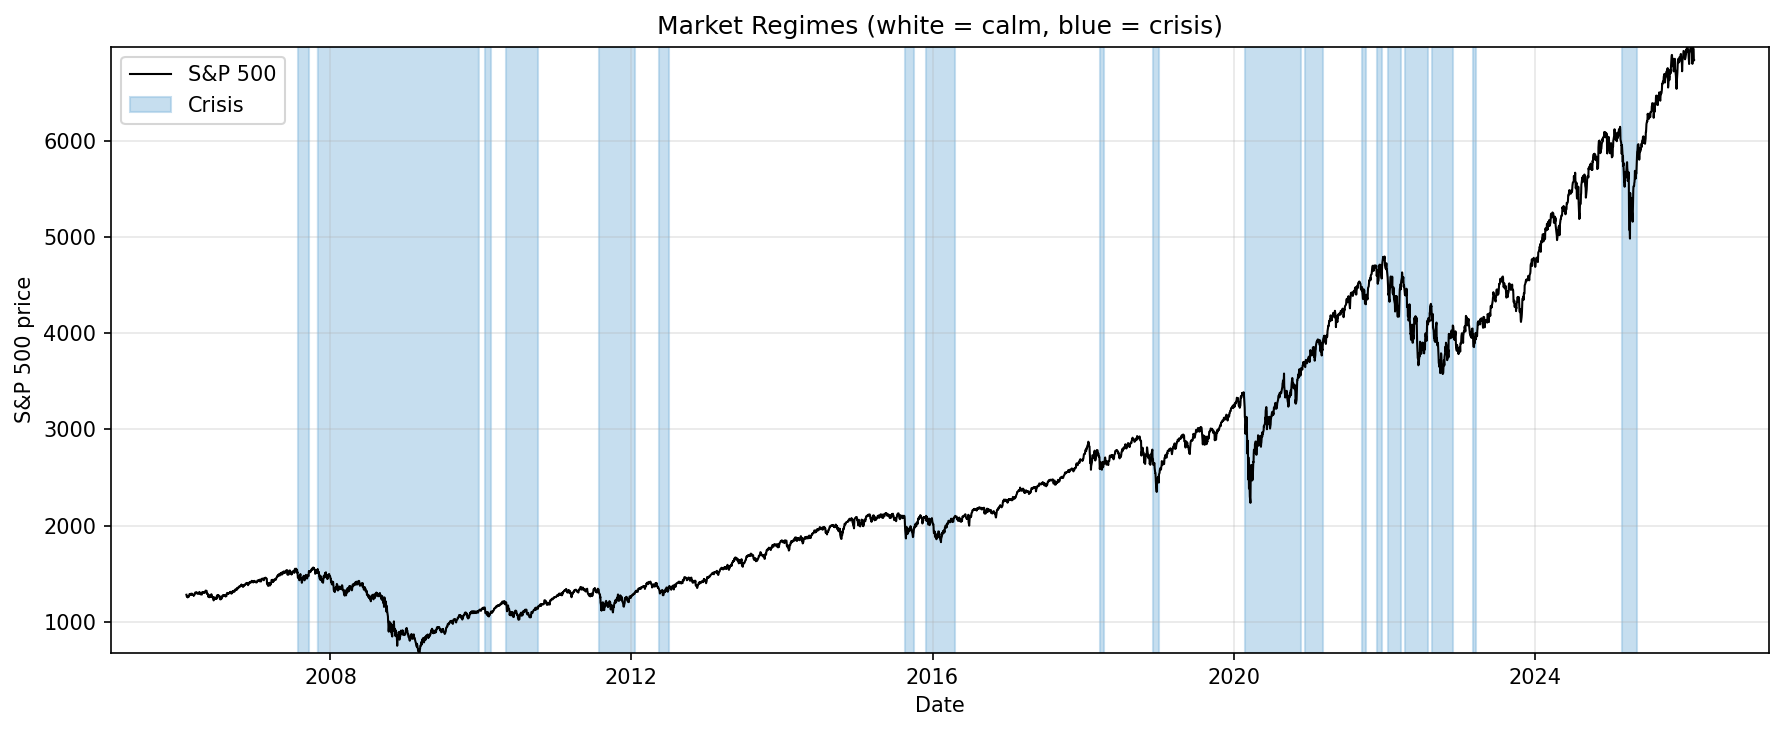

In [3]:
display(p1["feature_summary"].round(3))

# S&P 500 coloured by regime (white = calm, blue = crisis).
display(Image(filename=str(config.FIGURES_DIR / "regime_visualization_sp500.png")))

## Phase 2 - Anatomy of risk (marginal analysis)

We build the equal-weight portfolio (16 equities/ETFs + a duration-based 10Y/2Y bond sleeve),
split the returns by regime, and compute conditional **mean, volatility, skewness and kurtosis**.

In [4]:
from stress_engine.data.portfolio import Portfolio

portfolio = Portfolio()
p2 = pipeline.phase2_marginal_analysis(portfolio, regime_model.regimes)

print("Marginal statistics (first rows):")
display(p2["marginal_stats"].head(10))

print("\nVolatility amplification in crisis (top 8 assets):")
display(p2["vol_comparison"].head(8).round(3))

22:09:12 | INFO    | stress_engine.data.market_data | Loading cached equities: equities_adj_close_AAPL_AMZN_BAC_BRK-B_CVX_ENPH_GLD_GME_GOOGL_JNJ_JPM_MSFT_NVDA_PG_XOM_HYG.csv
22:09:12 | INFO    | stress_engine.data.market_data | Loading cached yields: us_yields_GS10_GS2.csv
22:09:12 | INFO    | stress_engine.data.portfolio | Built asset return matrix: 18 assets, 5061 rows.
22:09:12 | INFO    | stress_engine.pipeline | Phase 2: marginal risk analysis by regime.


Marginal statistics (first rows):


,Asset,Regime,Mean Return,Volatility,Skewness,Kurtosis,N Obs
0,AAPL,CALM,0.0015,0.0159,0.1503,4.5447,3478
1,AAPL,CRISIS,0.0004,0.0269,0.0179,3.9762,1563
2,AMZN,CALM,0.0015,0.0199,1.2500,25.7773,3478
3,AMZN,CRISIS,0.0005,0.0309,0.6698,6.0285,1563
4,BAC,CALM,0.0010,0.0149,0.1230,2.2622,3478
5,BAC,CRISIS,-0.0004,0.0479,0.6987,10.4015,1563
6,BRK-B,CALM,0.0007,0.0090,0.1154,2.8624,3478
7,BRK-B,CRISIS,0.0002,0.0202,0.7188,9.3447,1563
8,CVX,CALM,0.0005,0.0122,-0.2709,1.6366,3478
9,CVX,CRISIS,0.0006,0.0267,0.1305,12.2623,1563



Volatility amplification in crisis (top 8 assets):


,Asset,Volatility CALM,Volatility CRISIS,Ratio (Crisis/Calm),% Change
0,BAC,0.0150,0.0480,3.2040,220.3710
1,HYG,0.0030,0.0110,3.1360,213.5860
2,JPM,0.0130,0.0370,2.9100,191.0420
3,GS2,0.0010,0.0010,2.3270,132.7240
4,BRK-B,0.0090,0.0200,2.2420,124.1840
5,CVX,0.0120,0.0270,2.1930,119.3130
6,XOM,0.0120,0.0240,2.0590,105.9450
7,GME,0.0410,0.0790,1.9040,90.3520


**Question (brief):** how much does High Yield (HYG) volatility rise from calm to crisis,
and is Gold (GLD) still a safe haven?

In [5]:
display(p2["key_assets"].round(3))

def vol_increase(asset):
    k = p2["key_assets"]
    calm = k[(k.Asset == asset) & (k.Regime == config.CALM)]["Volatility (%)"].iloc[0]
    crisis = k[(k.Asset == asset) & (k.Regime == config.CRISIS)]["Volatility (%)"].iloc[0]
    return calm, crisis, (crisis / calm - 1) * 100

for asset in config.KEY_ASSETS:
    calm, crisis, inc = vol_increase(asset)
    print(f"{asset}: volatility {calm:.2f}% -> {crisis:.2f}% ({inc:+.0f}%)")

,Asset,Regime,Mean (%),Volatility (%),Skewness,Kurtosis,VaR 99%,CVaR 99%
0,GLD,CALM,0.0380,1.0070,-0.7880,8.1590,-0.0270,-0.0410
1,GLD,CRISIS,0.0700,1.4040,0.0880,4.5870,-0.0380,-0.0480
2,HYG,CALM,0.0260,0.3500,-0.0850,3.7170,-0.0100,-0.0120
3,HYG,CRISIS,0.0120,1.0960,0.5990,18.7610,-0.0360,-0.0480


HYG: volatility 0.35% -> 1.10% (+214%)
GLD: volatility 1.01% -> 1.40% (+40%)


**Reading:** HYG volatility rises sharply in crisis, confirming it is pro-cyclical and
credit-sensitive - it amplifies risk exactly when diversification is needed. Gold's volatility
is far more stable and it is not systematically dumped, so it acts as a *partial* hedge rather
than a guaranteed refuge.

## Phase 3 - When diversification fails (copulas)

We compute the **Pearson correlation** matrices per regime and calibrate the copulas:
a **Gaussian copula** in calm and a **Student-t copula** in crisis. The Student-t copula has
positive **tail dependence** (a Gaussian copula has zero), so it reproduces the joint crashes
that erase diversification.

22:09:12 | INFO    | stress_engine.pipeline | Phase 3: dependence structure (correlations and copulas).
22:09:12 | INFO    | stress_engine.models.copulas | Calibrated Gaussian copula for CALM regime.
22:09:13 | INFO    | stress_engine.models.copulas | Calibrated Student-t copula for CRISIS: dof=10.6, mean tail dep=0.067.
22:09:13 | INFO    | stress_engine.models.marginals | Fitted 18 Student-t marginals for CALM regime.
22:09:13 | INFO    | stress_engine.models.marginals | Fitted 18 Student-t marginals for CRISIS regime.


Average off-diagonal correlation increase (crisis - calm): +16 pp

CALM   : GaussianCopula
CRISIS : StudentTCopula | dof=10.6 | mean tail dependence=0.067


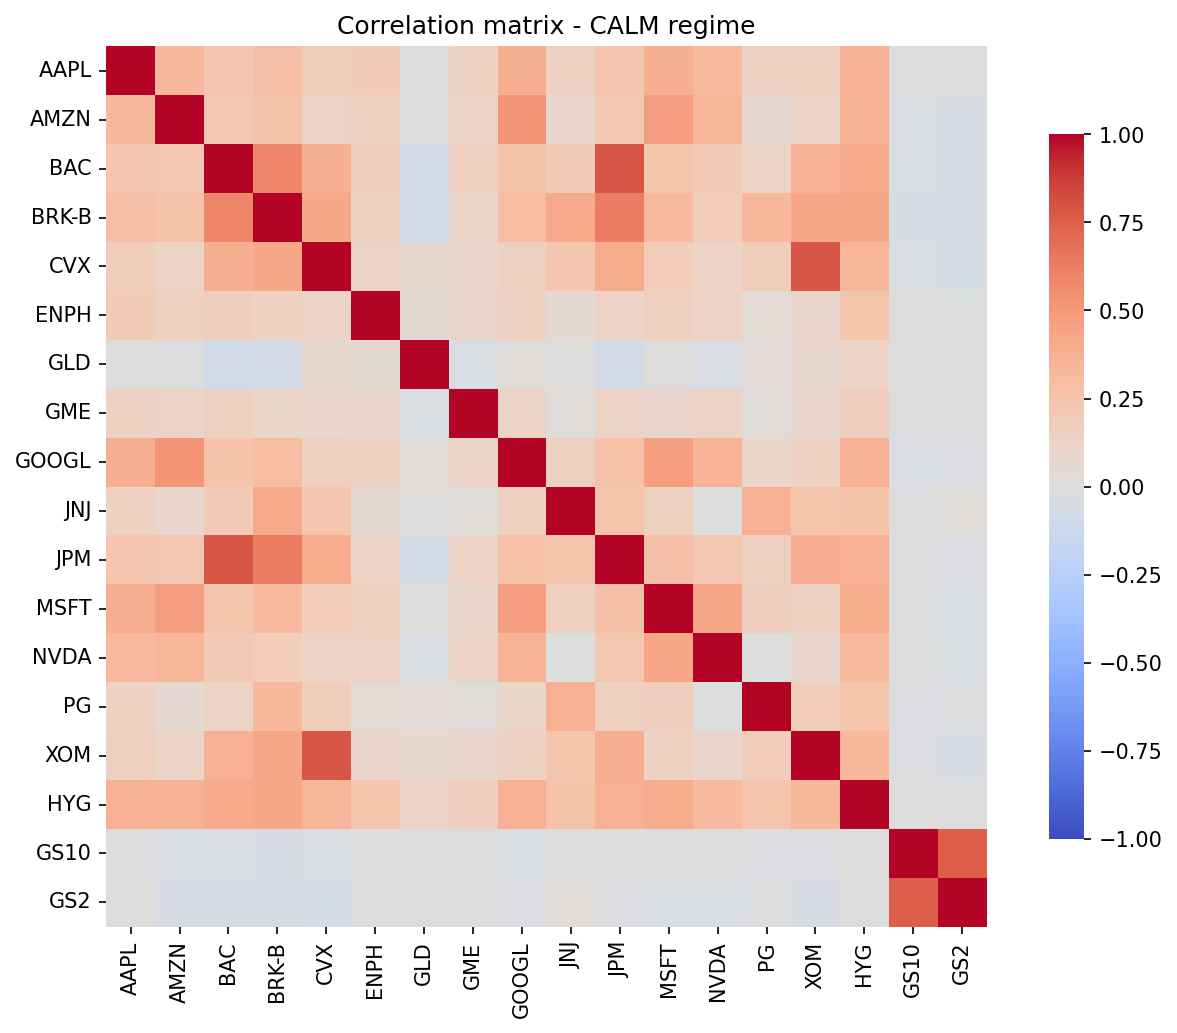

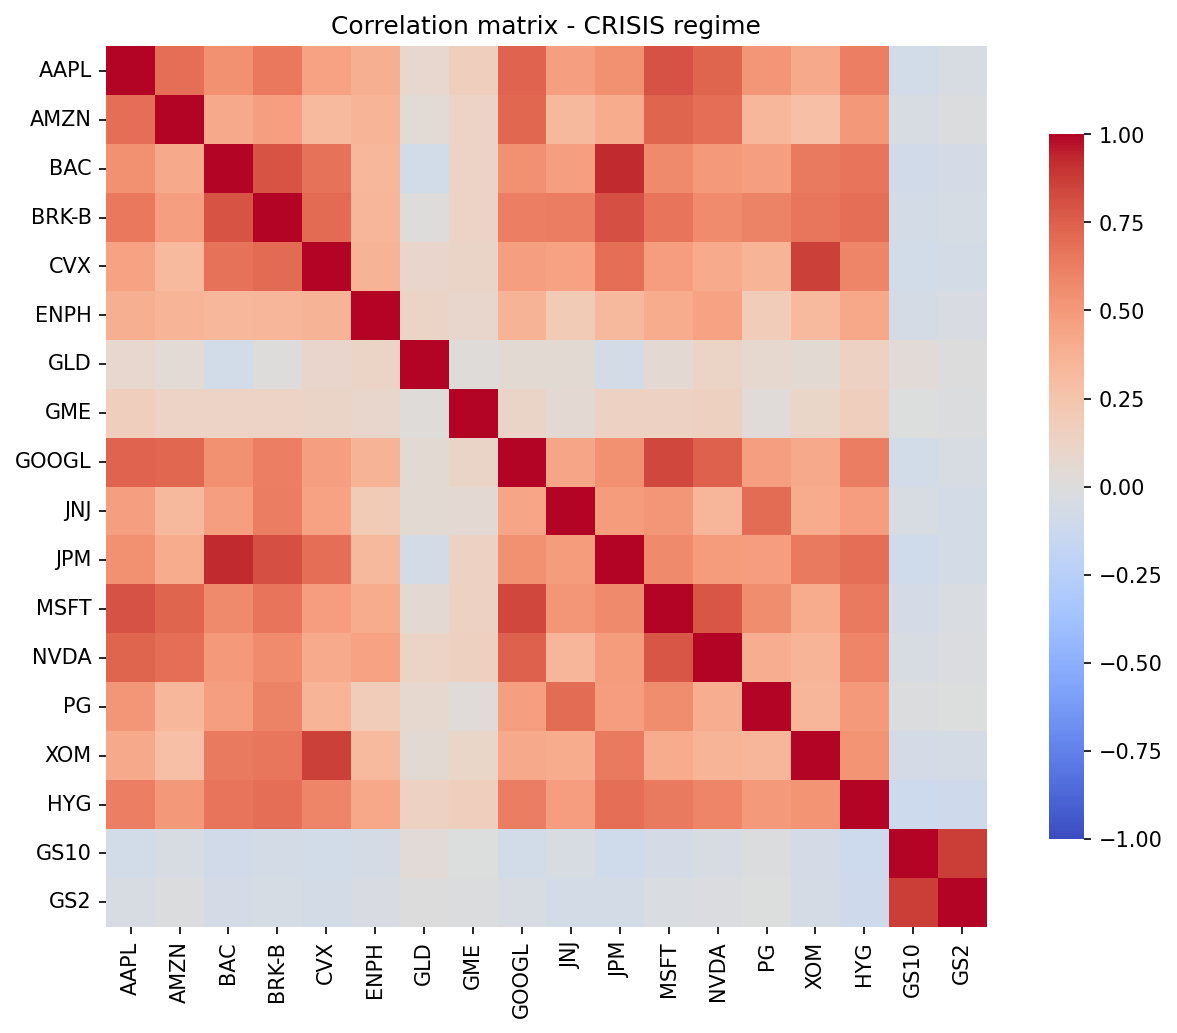

In [6]:
p3 = pipeline.phase3_dependence(p2["returns_by_regime"], make_plots=True)

print(f"Average off-diagonal correlation increase (crisis - calm): "
      f"+{p3['mean_corr_increase']*100:.0f} pp\n")

for regime, cop in p3["copulas"].items():
    extra = ""
    if hasattr(cop, "dof"):
        extra = f" | dof={cop.dof:.1f} | mean tail dependence={cop.mean_tail_dependence():.3f}"
    print(f"{regime:7s}: {type(cop).__name__}{extra}")

display(Image(filename=str(config.FIGURES_DIR / "correlation_matrix_calm.png")))
display(Image(filename=str(config.FIGURES_DIR / "correlation_matrix_crisis.png")))

### What really distinguishes a crisis regime?

The two regimes differ far more in **risk and dependence** than in average return:

- **Volatility amplification** across every asset.
- **Correlation convergence** - off-diagonal correlations jump towards one.
- **Fatter tails** (higher kurtosis) and material **tail dependence** in the Student-t copula.

Average return is only mildly lower in crisis; it is the *risk structure*, not the mean, that
changes - and that is precisely what breaks diversification.

## Phase 4 - The simulation engine

The Monte Carlo engine, for each path and day, (1) evolves the regime with the HMM transition
matrix and (2) draws multi-asset returns from the copula and Student-t marginals of the active
regime. We validate it against the real equal-weight portfolio.

In [7]:
p4 = pipeline.phase4_simulation(
    portfolio, regime_model, p3["marginals"], p3["copulas"],
    n_paths=config.N_PATHS, n_days=config.N_DAYS, make_plots=True,
)

metrics_table = pd.DataFrame({
    "Real": p4["real_metrics"], "Simulated": p4["sim_metrics"],
})
print("Risk metrics - real vs simulated (VaR/CVaR are daily):")
display(metrics_table.round(4))

regime_table = pd.DataFrame({
    "Real": p4["real_regime_stats"], "Simulated": p4["sim_regime_stats"],
})
print("\nRegime reproduction - real vs simulated:")
display(regime_table.round(2))

22:09:13 | INFO    | stress_engine.pipeline | Phase 4: Monte Carlo simulation (10000 paths, 126 days).
22:10:54 | INFO    | stress_engine.models.simulator | Simulated 10000 paths x 126 days; crisis share=18.4%.


Risk metrics - real vs simulated (VaR/CVaR are daily):


,Real,Simulated
Mean Return (ann),0.1879,0.2029
Volatility (ann),0.1811,0.1715
Max Drawdown,-0.0950,-0.0957
VaR 99%,-0.0305,-0.0289
CVaR 99%,-0.0442,-0.0400



Regime reproduction - real vs simulated:


,Real,Simulated
%_calm,68.9900,81.6000
%_crisis,31.0100,18.4000
mean_duration_calm,173.9000,80.1600
mean_duration_crisis,82.2600,41.8900
n_switches,38.0000,0.8400


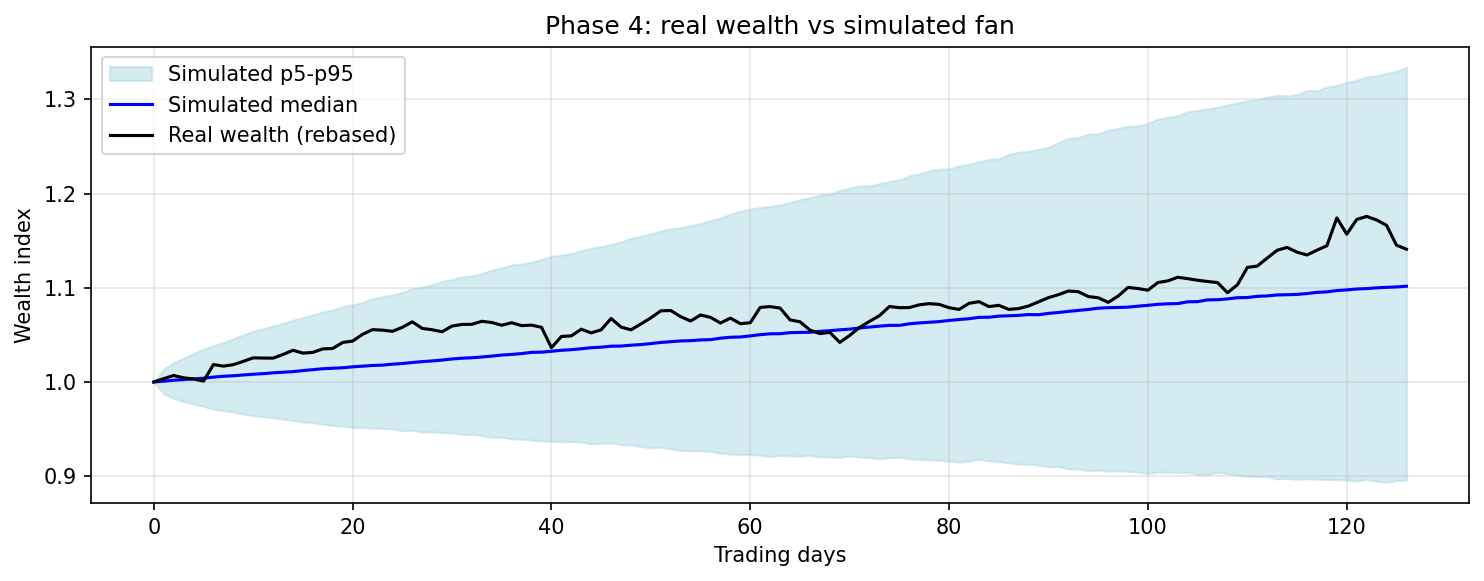

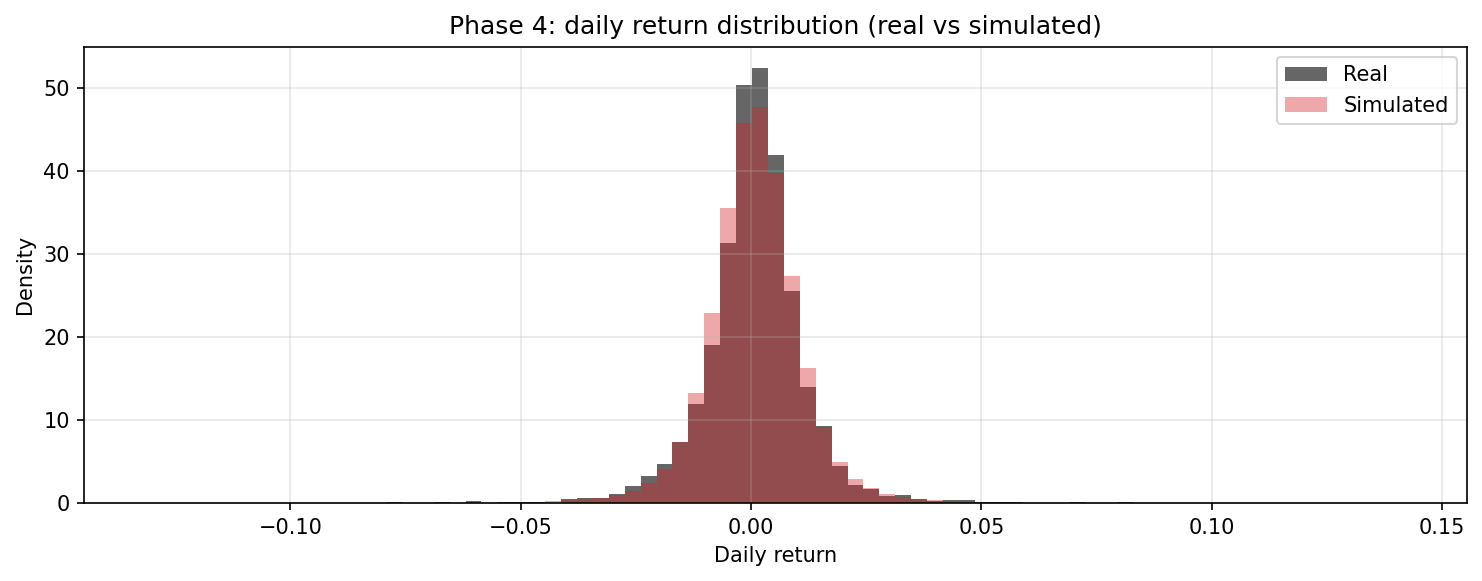

In [8]:
display(Image(filename=str(config.FIGURES_DIR / "phase4_wealth_fan.png")))
display(Image(filename=str(config.FIGURES_DIR / "phase4_returns_hist.png")))

**Reading:** the simulator reproduces the portfolio's daily volatility, 99% VaR/CVaR and the
horizon-matched maximum drawdown (real and simulated drawdowns are both measured over a
six-month window). The *regime* statistics are not on the same footing: the **real** figures
span the full ~20-year history, whereas the **simulated** figures are per six-month path started
in calm - so a single path accumulates less crisis time, shorter episodes and fewer switches than
the long historical record. The reassuring, comparable facts are that crises stay a substantial
minority of days and are highly persistent in both.

## Phase 5 - Stress scenarios (breaking the portfolio)

Three economically coherent scenarios force the market into crisis, amplify the volatility of
the relevant assets and, for systemic shocks, intensify the Student-t tail dependence:

1. **Stagflation 2022** - stocks and bonds fall together (rate shock).
2. **Credit Crisis 2008** - systemic credit stress; strong joint tail dependence.
3. **Liquidity Spiral** (proposed) - indiscriminate selling; even gold is liquidated.

22:10:56 | INFO    | stress_engine.pipeline | Phase 5: stress scenarios.
22:12:55 | INFO    | stress_engine.models.simulator | Simulated 10000 paths x 126 days; crisis share=94.4%.
22:12:55 | INFO    | stress_engine.evaluation.scenarios | Scenario 'Stagflation 2022': VaR99=-0.0535, CVaR99=-0.0707.
22:14:51 | INFO    | stress_engine.models.simulator | Simulated 10000 paths x 126 days; crisis share=96.2%.
22:14:52 | INFO    | stress_engine.evaluation.scenarios | Scenario 'Credit Crisis 2008': VaR99=-0.0615, CVaR99=-0.0834.
22:16:50 | INFO    | stress_engine.models.simulator | Simulated 10000 paths x 126 days; crisis share=96.2%.
22:16:50 | INFO    | stress_engine.evaluation.scenarios | Scenario 'Liquidity Spiral': VaR99=-0.0778, CVaR99=-0.1066.


Base vs stress scenarios (VaR/CVaR are daily):


,Base,Stagflation 2022,Credit Crisis 2008,Liquidity Spiral
VaR 99%,-0.0289,-0.0535,-0.0615,-0.0778
CVaR 99%,-0.0400,-0.0707,-0.0834,-0.1066
Volatility (ann),0.1715,0.3309,0.3717,0.4661
Max Drawdown,-0.0957,-0.2124,-0.2374,-0.2941


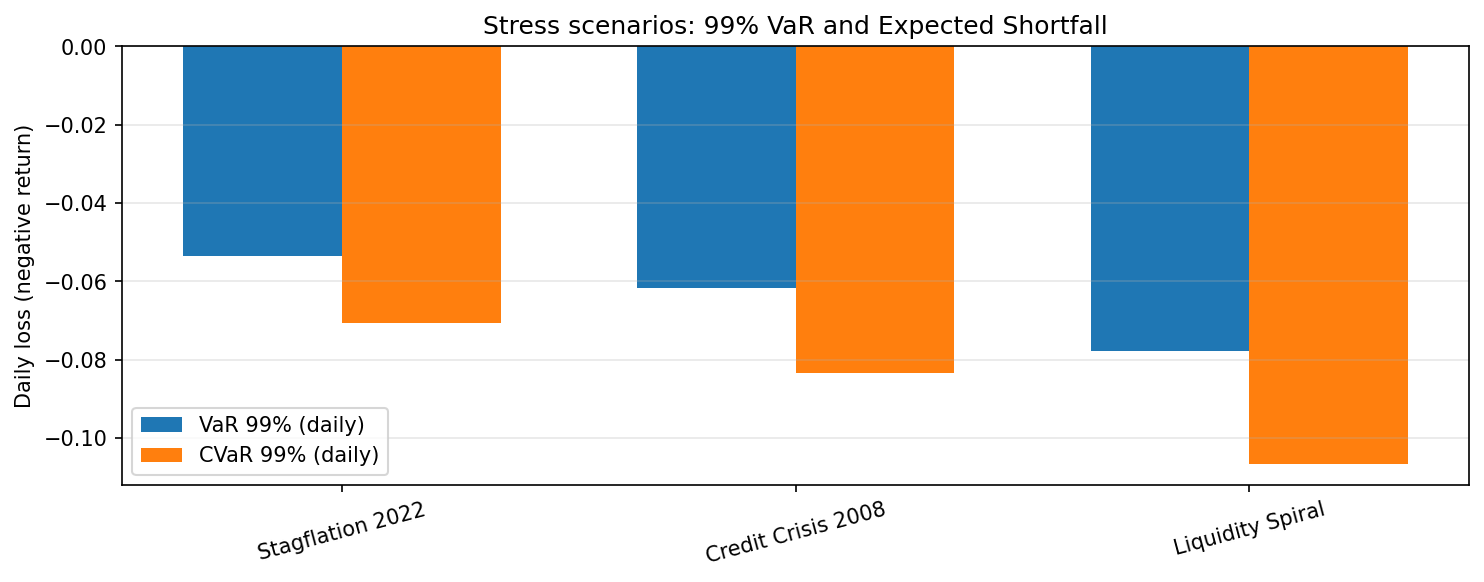

In [9]:
scenario_results = pipeline.phase5_stress(
    p3["marginals"], p3["copulas"],
    n_paths=config.N_PATHS, n_days=config.N_DAYS, make_plots=True,
)

rows = {"Base": p4["sim_metrics"]}
for s in scenario_results:
    rows[s["name"]] = s["metrics"]
stress_table = pd.DataFrame(rows).loc[
    ["VaR 99%", "CVaR 99%", "Volatility (ann)", "Max Drawdown"]
]
print("Base vs stress scenarios (VaR/CVaR are daily):")
display(stress_table.round(4))

display(Image(filename=str(config.FIGURES_DIR / "phase5_scenario_risk.png")))

Stagflation 2022 - In 2022 the classic stock/bond diversification failed: rising real rates repriced both equities and duration simultaneously. The scenario amplifies the volatility of the bond sleeve (GS10, GS2) and broad equities, keeping gold only mildly supportive.


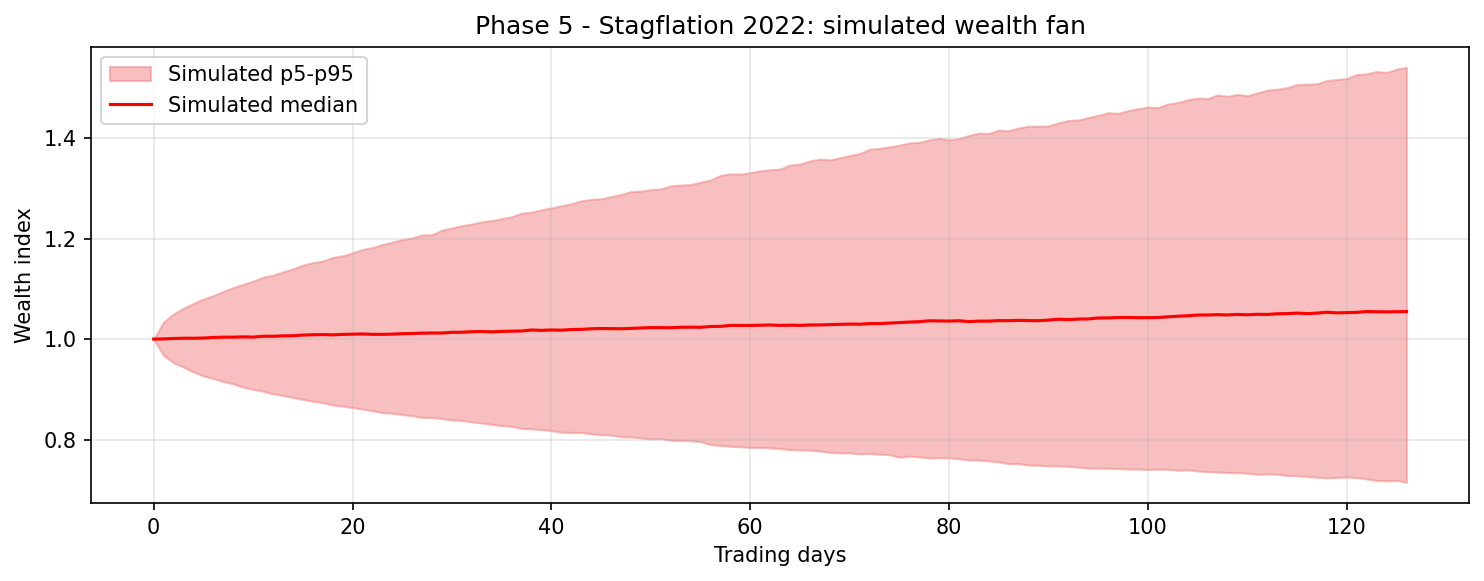

Credit Crisis 2008 - A 2008-style shock in which high-yield credit (HYG) and banks (BAC, JPM) lead the drawdown and correlations converge to one. The low copula degrees of freedom encode strong joint tail dependence: almost everything sells off together.


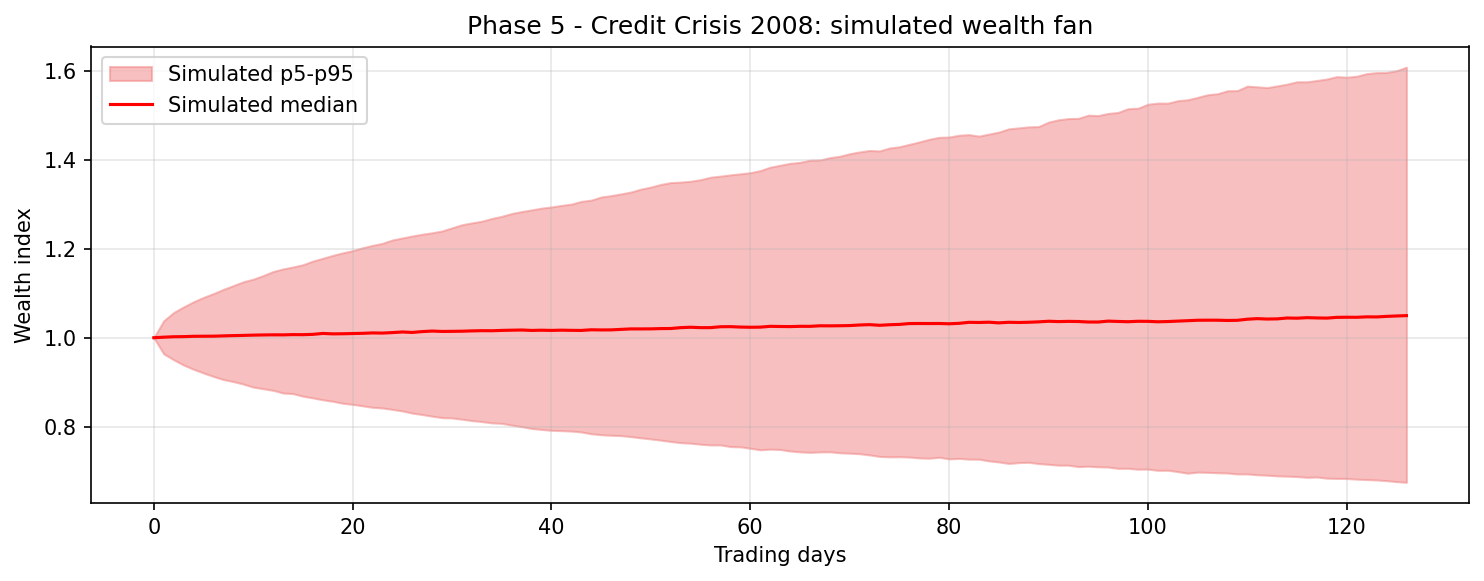

Liquidity Spiral - Proposed scenario. Under a liquidity spiral, funds meet redemptions by selling whatever they can, so even safe havens are liquidated. Extremely low copula degrees of freedom push tail dependence towards one and gold loses its refuge property (its volatility is amplified rather than dampened).


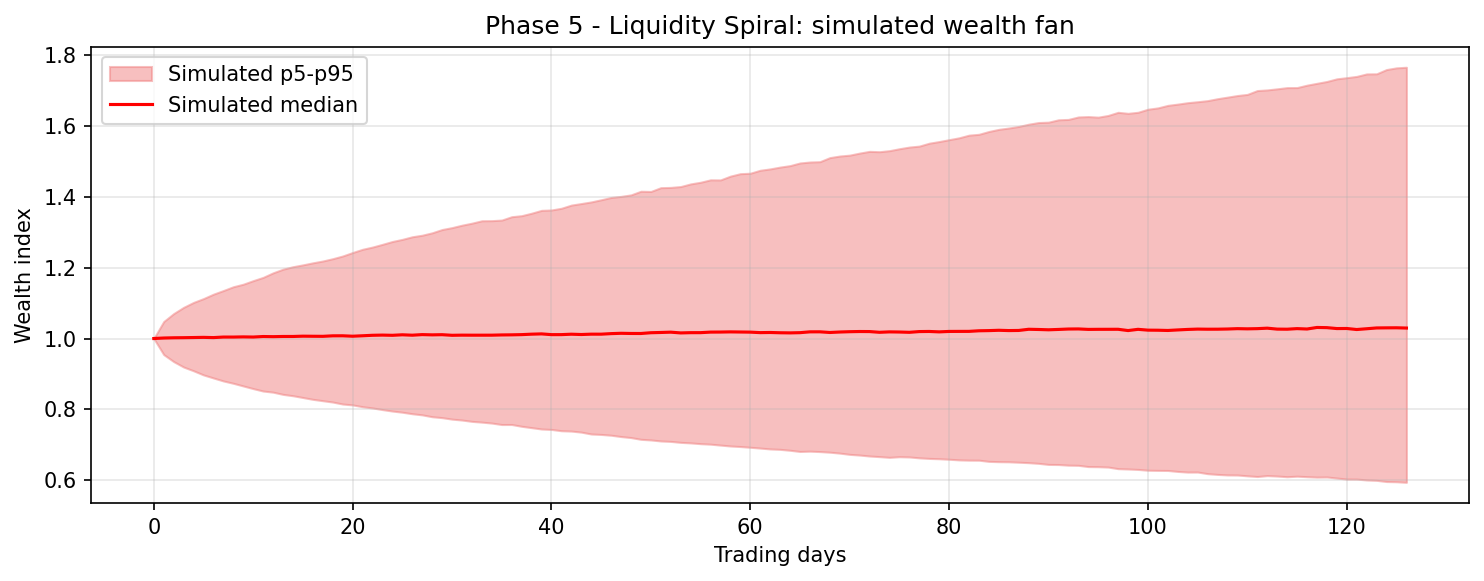

In [10]:
for s in scenario_results:
    slug = s["name"].lower().replace(" ", "_").replace("/", "_")
    print(s["name"], "-", s["rationale"])
    display(Image(filename=str(config.FIGURES_DIR / f"phase5_{slug}_wealth_fan.png")))

## Executive report

Finally we assemble the results and generate the three-page executive summary
(`report/INFORME_EJECUTIVO.pdf`) for the Risk Committee.

In [11]:
from stress_engine.reporting.executive_report import generate_report

results = {"portfolio": portfolio, **p1, **p2, **p3,
           "phase4": p4, "scenarios": scenario_results}
report_path = generate_report(results)
print(f"Executive report written to: {report_path}")
print(f"PDF: {report_path.with_suffix('.pdf')}")

22:17:01 | DEBUG   | fontTools.ttLib.ttFont | Reading 'maxp' table from disk
22:17:01 | DEBUG   | fontTools.ttLib.ttFont | Decompiling 'maxp' table
22:17:01 | DEBUG   | fontTools.subset.timer | Took 0.004s to load 'maxp'
22:17:01 | DEBUG   | fontTools.subset.timer | Took 0.000s to prune 'maxp'
22:17:01 | INFO    | fontTools.subset | maxp pruned
22:17:01 | INFO    | fontTools.subset | LTSH dropped
22:17:01 | INFO    | fontTools.subset | VDMX dropped
22:17:01 | INFO    | fontTools.subset | hdmx dropped
22:17:01 | DEBUG   | fontTools.ttLib.ttFont | Reading 'cmap' table from disk
22:17:01 | DEBUG   | fontTools.ttLib.ttFont | Decompiling 'cmap' table
22:17:01 | DEBUG   | fontTools.subset.timer | Took 0.003s to load 'cmap'
22:17:01 | DEBUG   | fontTools.subset.timer | Took 0.000s to prune 'cmap'
22:17:01 | INFO    | fontTools.subset | cmap pruned
22:17:01 | INFO    | fontTools.subset | fpgm dropped
22:17:01 | INFO    | fontTools.subset | prep dropped
22:17:01 | INFO    | fontTools.subset | c

Executive report written to: C:\Users\piett\OneDrive\Desktop\Pietro\Master MIAX\Clases\2.Introduccion a los Sistemas Financieros\Tareas\Riesgos\report\INFORME_EJECUTIVO.md
PDF: C:\Users\piett\OneDrive\Desktop\Pietro\Master MIAX\Clases\2.Introduccion a los Sistemas Financieros\Tareas\Riesgos\report\INFORME_EJECUTIVO.pdf


## Conclusions

- The market alternates between a **calm** regime and a **sustained crisis** regime; the HMM
  identifies them from interpretable drivers.
- In crisis, **volatility rises, correlations converge and tails fatten** - diversification
  collapses, captured by the Student-t copula's tail dependence.
- The Monte Carlo engine reproduces the real portfolio's tail risk and lets us **stress the
  portfolio** under coherent adverse scenarios, quantifying losses with 99% VaR and CVaR.
- **Risk-management takeaway:** monitor regime transitions, cut pro-cyclical exposure early,
  and size limits to the stress tail rather than to calm-market VaR.